## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Load Dataset


In [2]:
df=pd.read_csv('D:\Day-3-task-Elevate-Lab---Nishita-kanojiya\dataset\house_prices.csv')
df

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Nishita\AppData\Local\Temp\ipykernel_27556\2615995308.py:1: SyntaxWarning: invalid escape sequence '\D'
  df=pd.read_csv('D:\Day-3-task-Elevate-Lab---Nishita-kanojiya\dataset\house_prices.csv')


,area,bedrooms,age,price
0,814,5,10,303499.0
1,2457,1,27,386971.0
2,2170,5,14,490841.0
3,1653,1,20,241470.0
4,1639,4,13,329780.0
...,...,...,...,...
95,1291,1,15,188369.0
96,1174,2,25,250197.0
97,2237,1,13,374037.0
98,2128,2,8,410136.0


In [3]:
df.head()

,area,bedrooms,age,price
0,814,5,10,303499.0
1,2457,1,27,386971.0
2,2170,5,14,490841.0
3,1653,1,20,241470.0
4,1639,4,13,329780.0


In [4]:
df.tail()

,area,bedrooms,age,price
95,1291,1,15,188369.0
96,1174,2,25,250197.0
97,2237,1,13,374037.0
98,2128,2,8,410136.0
99,935,5,0,398407.0


## 3. Understand the data

In [5]:
print('Shape:', df.shape)
print('\nColumns:', df.columns.tolist())
print('\nData types:')
display(df.dtypes)
print('\nMissing values:')
display(df.isnull().sum())
print('\nSummary statistics:')
display(df.describe(include='all').T)

Shape: (100, 4)

Columns: ['area', 'bedrooms', 'age', 'price']

Data types:


area          int64
bedrooms      int64
age           int64
price       float64
dtype: object


Missing values:


area        0
bedrooms    0
age         0
price       0
dtype: int64


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
area,100.0,1863.69,654.693786,705.0,1373.00,1847.0,2430.00,2941.0
bedrooms,100.0,2.96,1.347800,1.0,2.00,3.0,4.00,5.0
age,100.0,13.86,8.047862,0.0,7.75,14.0,20.25,29.0
price,100.0,388638.77,132890.000915,158397.0,281408.00,396774.0,500423.50,736063.0


## 4. Preprocess the Data



In [ ]:

numeric_df = df.select_dtypes(include=np.number)


numeric_df = numeric_df.dropna()

# Separate features and target
X = numeric_df.drop("price", axis=1)
y = numeric_df["price"]

print("Target: price")
print("Features:", X.columns.tolist())
print("Rows after preprocessing:", len(numeric_df))

Target: price
Features: ['area', 'bedrooms', 'age']
Rows after preprocessing: 100


## 5. Train-Test Split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))

Training samples: 80
Testing samples: 20


## 6. Train Multiple Linear Regression Model

In [9]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('Model trained successfully.')
print('Intercept:', model.intercept_)

Model trained successfully.
Intercept: 59825.50796933577


## 7. Evaluate the Model

- **MAE:** Average absolute prediction error.
- **MSE:** Average squared prediction error.
- **R²:** Proportion of target variance explained by the model.

In [10]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE  : {mae:.2f}')
print(f'MSE  : {mse:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'R²   : {r2:.4f}')

MAE  : 21055.37
MSE  : 675043530.84
RMSE : 25981.60
R²   : 0.9685


## 8. Interpret Model Coefficients



In [11]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values('Coefficient', key=lambda s: s.abs(), ascending=False)

display(coefficients)
print('Intercept:', model.intercept_)

,Feature,Coefficient
1,bedrooms,27079.575469
2,age,-5204.621511
0,area,172.516092


Intercept: 59825.50796933577


## 9. Actual vs Predicted Values

In [12]:
comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
display(comparison.head(10))

,Actual,Predicted
0,529919.0,543475.914762
1,406824.0,363870.742923
2,481985.0,478110.985265
3,736063.0,690113.774691
4,210844.0,233169.976037
5,378966.0,412252.580990
6,212196.0,237918.461235
7,623483.0,646292.370937
8,385361.0,398949.787048
9,303499.0,283605.268796


## 10. Actual vs Predicted Plot



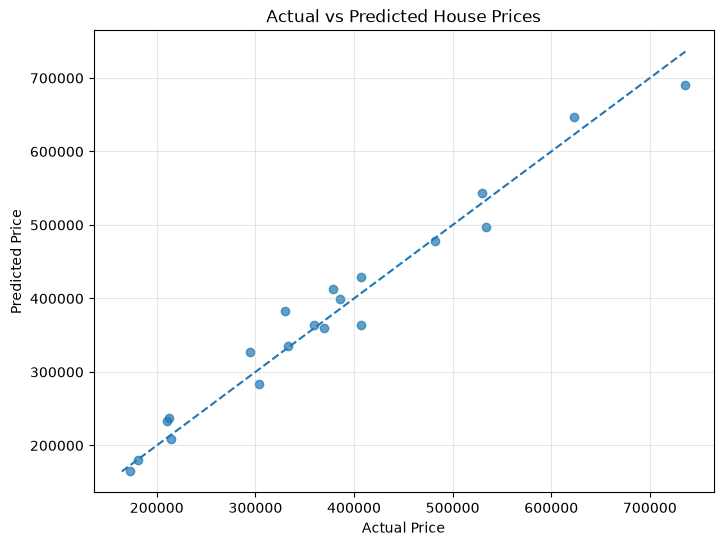

In [18]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle='--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices')
plt.grid(True, alpha=0.3)
plt.show()

#save the figure 


## 11. Simple Linear Regression



In [14]:
simple_feature = X.columns[0]
X_simple = X[[simple_feature]]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)
y_pred_s = simple_model.predict(X_test_s)

print('Feature used:', simple_feature)
print(f'Simple Linear Regression R²: {r2_score(y_test_s, y_pred_s):.4f}')

Feature used: area
Simple Linear Regression R²: 0.8376


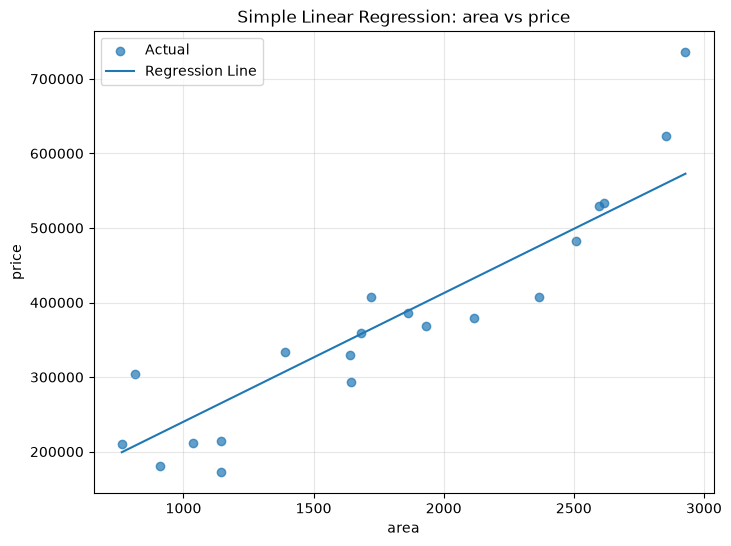

In [16]:
import os

# Create output folder if it doesn't exist
os.makedirs("../outputs", exist_ok=True)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_test_s[simple_feature],
    y_test_s,
    alpha=0.7,
    label="Actual"
)


order = np.argsort(X_test_s[simple_feature].values)

x_sorted = X_test_s[simple_feature].values[order]
y_sorted = y_pred_s[order]

plt.plot(
    x_sorted,
    y_sorted,
    label="Regression Line"
)

plt.xlabel(simple_feature)
plt.ylabel(TARGET_COLUMN)
plt.title(f"Simple Linear Regression: {simple_feature} vs {TARGET_COLUMN}")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the figure
plt.savefig("../outputs/simple_linear_regression.png", dpi=300, bbox_inches="tight")

plt.show()

## 12. Final Interpretation

- The model learns the relationship between numerical features and house price.
- MAE shows average absolute prediction error.
- MSE penalizes larger errors more strongly.
- R² indicates how much target variation is explained by the model.
- Coefficients show feature contribution while other features are held constant.
- Simple regression uses one feature; multiple regression uses two or more features.